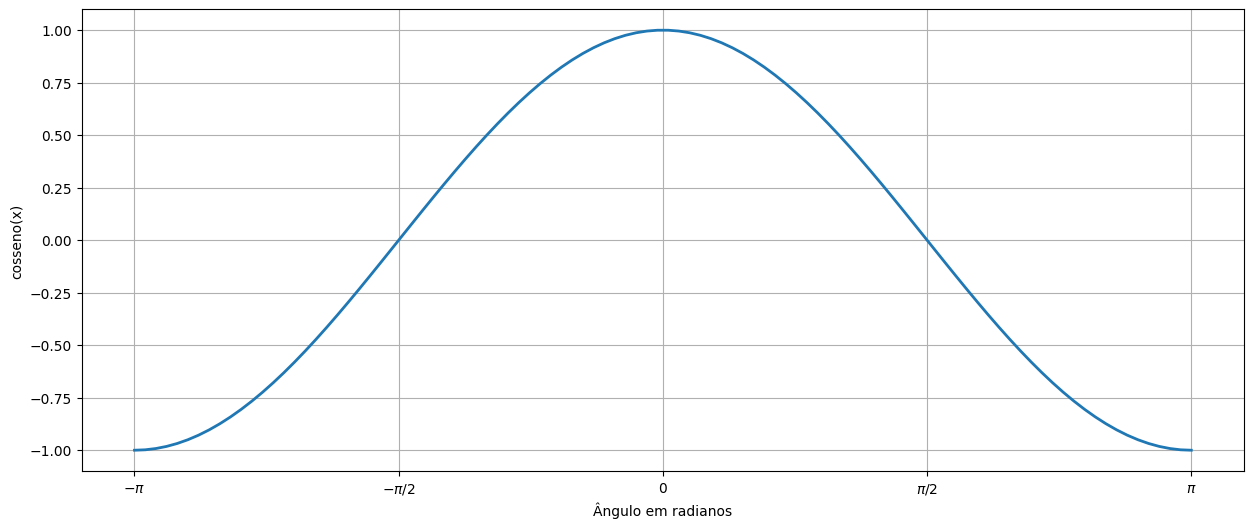

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def grafico_em_radianos(fig, ax):
  fig.set_size_inches(15,6)

  # Ajustar o eixo x para que mostre radianos
  custom_ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
  custom_tick_labels = [r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$']
  ax.set_xticks(custom_ticks)
  ax.set_xticklabels(custom_tick_labels)

  # Adicionar labels
  ax.set_xlabel('Ângulo em radianos')
  ax.set_ylabel('cosseno(x)')
  ax.grid(True)

x = np.linspace(-np.pi, np.pi, 100) # 100 pontos
y = np.cos(x) # Alterado aqui de np.sin para np.cos

fig, ax = plt.subplots()
ax.plot(x, y, linewidth=2.0)

grafico_em_radianos(fig, ax)

plt.show()

2. Série de Taylor do seno
$$\cos(x) = \sum_{n=0}^{\infty} \frac{(-1)^n}{(2n)!} x^{2n} = 1 - \frac{x^2}{2!} + \frac{x^4}{4!} - \frac{x^6}{6!} + \dots$$

In [28]:
import math
import numpy as np

def cosseno(x, n=5):
    numerador = 1
    denominador = 1
    soma = 1
    sinal = 1
    for i in range(1, n):
        fator = 2 * i
        sinal = -1 * sinal
        numerador = x * x * numerador
        denominador = fator * (fator - 1) * denominador
        soma += sinal * numerador / denominador
    return soma


In [30]:
np.cos(np.pi/3)

np.float64(0.5000000000000001)

In [31]:
cosseno(np.pi/3, 3)

np.float64(0.501796201500181)

In [32]:
cosseno(np.pi/3, 5)

np.float64(0.500000433432915)

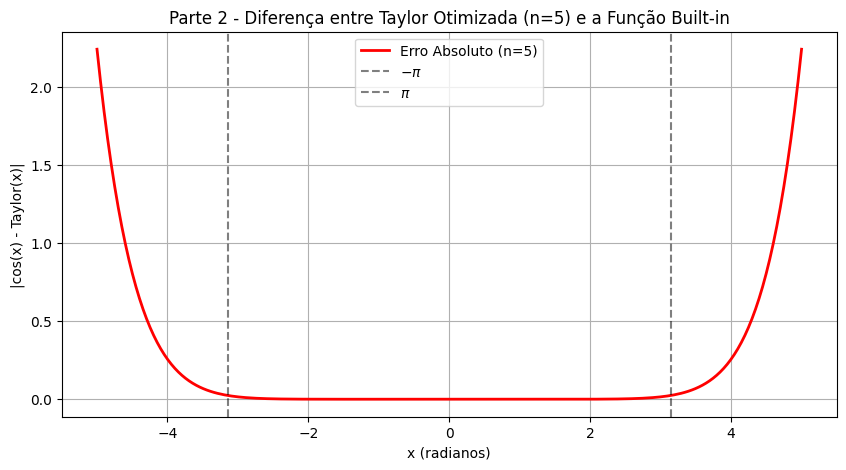

Faixa correta: Entre -π e π (aproximadamente de -3.14 a 3.14 radianos)


In [42]:
x_cosseno = np.linspace(-5, 5, 200)
cosseno_real = np.cos(x_cosseno)

cosseno_taylor = np.array([cosseno(xi, n=5) for xi in x_cosseno])


erro = np.abs(cosseno_real - cosseno_taylor)


plt.figure(figsize=(10, 5))

plt.plot(x_cosseno, erro, label='Erro Absoluto (n=5)', color='red', linewidth=2)

plt.axvline(x=-np.pi, color='black', linestyle='--', alpha=0.5, label=r'$-\pi$')
plt.axvline(x=np.pi, color='black', linestyle='--', alpha=0.5, label=r'$\pi$')
plt.title('Parte 2 - Diferença entre Taylor Otimizada (n=5) e a Função Built-in')
plt.xlabel('x (radianos)')
plt.ylabel('|cos(x) - Taylor(x)|')
plt.grid(True)
plt.legend()
plt.show()

print("Faixa correta: Entre -π e π (aproximadamente de -3.14 a 3.14 radianos)")

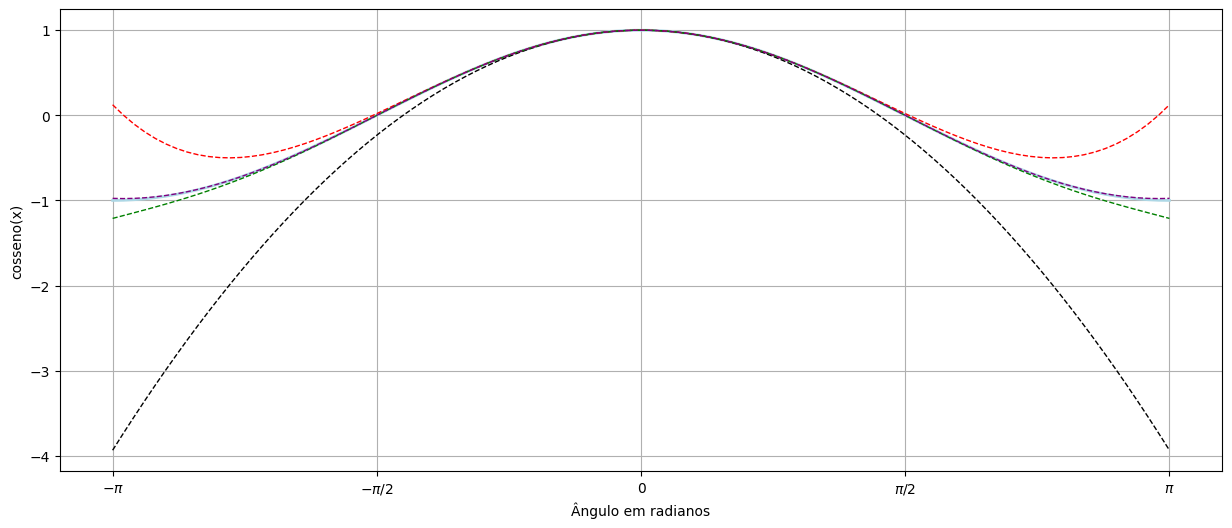

In [11]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-np.pi, np.pi, 100)
y1 = np.cos(x)
y2 = cosseno(x, 2)
y3 = cosseno(x, 3)
y4 = cosseno(x, 4)
y5 = cosseno(x, 5)

fig, ax = plt.subplots()
ax.plot(x, y1, linewidth=2.0, color='lightblue')
ax.plot(x, y2, linewidth=1.0, color='black', linestyle='dashed')
ax.plot(x, y3, linewidth=1.0, color='red', linestyle='dashed')
ax.plot(x, y4, linewidth=1.0, color='green', linestyle='dashed')
ax.plot(x, y5, linewidth=1.0, color='purple', linestyle='dashed')

grafico_em_radianos(fig, ax)

# Display the plot
plt.show()

Cosseno otimizado

In [18]:
import math
import numpy as np

def cosseno_otimizado(x, n = 3):
  # Para o cosseno, as condições iniciais começam em 1
  numerador = 1
  denominador = 1
  soma = 1 / denominador
  sinal = 1

  for i in range(1, n):
    fator = 2 * i
    sinal = -1 * sinal

    numerador = x * x * numerador

    denominador = fator * (fator - 1) * denominador

    soma += sinal * numerador / denominador
  return soma

In [19]:
cosseno_otimizado(np.pi/3,5)

0.500000433432915

Cosseno otimizado com tabela

In [20]:
import math
import numpy as np

def cosseno_otimizado_com_tabela(x, n = 5):

  x_y_table = {
    -np.pi: -1,    # cos(-π) = -1
    -np.pi/2: 0,   # cos(-π/2) = 0
    0: 1,          # cos(0) = 1
    np.pi/2: 0,    # cos(π/2) = 0
    np.pi: -1      # cos(π) = -1
  }

  for chave, valor in x_y_table.items():
    if math.isclose(chave, x):
      return valor

  #Condições iniciais
  numerador = 1
  denominador = 1
  soma = numerador / denominador
  sinal = 1

  for i in range(1, n):
    fator = 2 * i       #Avança de 2 em 2
    sinal = -1 * sinal

    numerador = x * x * numerador
    denominador = fator * (fator - 1) * denominador

    a_n = sinal * numerador / denominador
    soma = soma + a_n

  return soma




Teste tabela (π/2): 0
Teste Taylor (π/3): 0.500000433432915


In [21]:

print("Teste tabela (π/2):", cosseno_otimizado_com_tabela(np.pi/2))

print("Teste Taylor (π/3):", cosseno_otimizado_com_tabela(np.pi/3))

Teste tabela (π/2): 0
Teste Taylor (π/3): 0.500000433432915


<>:20: SyntaxWarning: invalid escape sequence '\ '
<>:20: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1459/4142779761.py:20: SyntaxWarning: invalid escape sequence '\ '
  print("Faixa correta: Entre -10 e 10\ radianos.")


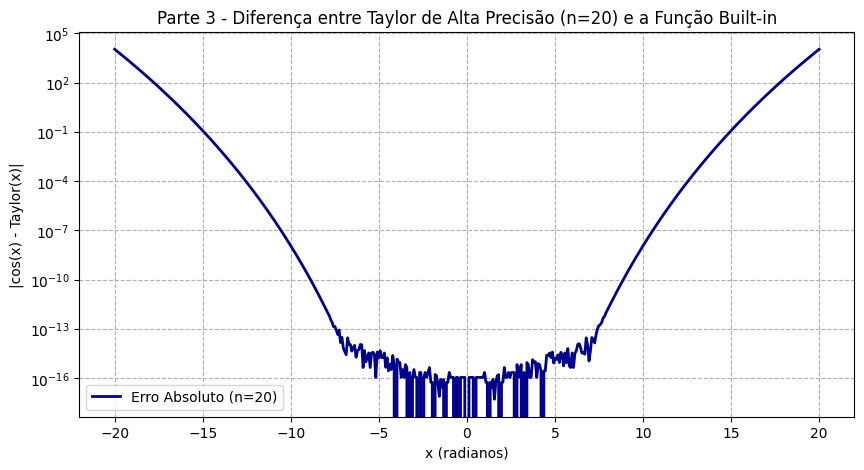

Faixa correta: Entre -10 e 10\ radianos.


In [40]:
# Utilizando N = 20
x_angulos = np.linspace(-20, 20, 500)
cosseno_real = np.cos(x_angulos)
cosseno_taylor = np.array([cosseno(xi, n=20) for xi in x_angulos])


erro_preciso = np.abs(cosseno_real - cosseno_taylor)


plt.figure(figsize=(10, 5))
plt.plot(x_angulos, erro_preciso, label='Erro Absoluto (n=20)', color='darkblue', linewidth=2)
plt.title('Parte 3 - Diferença entre Taylor de Alta Precisão (n=20) e a Função Built-in')
plt.xlabel('x (radianos)')
plt.ylabel('|cos(x) - Taylor(x)|')
plt.yscale('log')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

print("Faixa correta: Entre -10 e 10 radianos.")